In [1]:
import sys
# sys.path.insert(0, '../../Utilities/')

# from jax.example_libraries import optimizers
import jax.numpy as jnp
import numpy as np
from jax import grad, jit, vmap, value_and_grad, hessian
from jax import random
from functools import partial
import flax.linen as nn
import jax
import optax
import pickle
from datetime import datetime
import os
import numpy as np
from scipy import sparse
import time
from jax import grad, hessian, jit, vmap, pmap
from jax.tree_util import tree_leaves
from datetime import datetime
import matplotlib.pyplot as plt
import pickle
import flax.linen as nn
import optax
import optax.tree_utils as otu
from NN_class import MLP
from my_helpers import plot_u_theta, plot_kh, plot_loss_history
from functools import partial
from Pwp_class import PiecewiseLinearPolynomials
from minmax_opt_class import pytree_l2_norm, MinMaxOptProb
from seq_minmax_opt_class import SeqMinMaxOptProb


import matplotlib.pyplot as plt
import scipy.io
from scipy.interpolate import griddata

import time
import matplotlib.gridspec as gridspec
from mpl_toolkits.axes_grid1 import make_axes_locatable
import mpmath


import os
os.environ['ENABLE_PJRT_COMPATIBILITY'] = '1'

jax.config.update('jax_platform_name', 'cpu')
os.environ['OMP_NUM_THREADS'] = str(os.cpu_count())

In [2]:
def u0(x):
    return -jnp.sin(jnp.pi*x)

# Boundary at x=-1
def u1(x):
    return 0
vmap_u1 = vmap(u1, in_axes=0, out_axes=0)

# Boundary at x=2
def u2(x):
    return 0
vmap_u2 = vmap(u2, in_axes=0, out_axes=0)

def res_visc(u_quad, u_t, u_x, u_xx, nu):
    return u_t + u_quad * u_x - nu*u_xx
def res(u_quad, u_t, u_x):
    return u_t + u_quad * u_x


t_min = 0
t_max = 1
x_min = -1
x_max = 1
Nt = 101
Nx = 301
layers = [2, 50, 50, 50, 50, 50, 1]
hidden_dims_list = [layers[1:-1]]

Metal device set to: Apple M4 Max


W0000 00:00:1753568247.452435 17347808 mps_client.cc:510] WARNING: JAX Apple GPU support is experimental and not all JAX functionality is correctly supported!
I0000 00:00:1753568247.459504 17347808 service.cc:145] XLA service 0x600003e49400 initialized for platform METAL (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1753568247.459514 17347808 service.cc:153]   StreamExecutor device (0): Metal, <undefined>
I0000 00:00:1753568247.460381 17347808 mps_client.cc:406] Using Simple allocator.
I0000 00:00:1753568247.460388 17347808 mps_client.cc:384] XLA backend will use up to 103078739968 bytes on device 0 for SimpleAllocator.


In [3]:
notes = '''This notebook is for computing Burgers equation with sin init, \n
featured with initial gamma = 0.0, f_opt_kh = 1, use_a = True, and L1_regularization = 0.\n
We use warmup_exponential_decay_schedule for the learning rate.\n
We use normal sampling to optimize k_h with sigma = 0.2.
In this copy, we train 50000 epoches. '''
print(notes)

This notebook is for computing Burgers equation with sin init, 

featured with initial gamma = 0.0, f_opt_kh = 1, use_a = True, and L1_regularization = 0.

We use warmup_exponential_decay_schedule for the learning rate.

We use normal sampling to optimize k_h with sigma = 0.2.
In this copy, we train 50000 epoches. 


In [4]:
seq_trainer = SeqMinMaxOptProb(
    num_segments=5,
    total_t_min=t_min,
    total_t_max=t_max,
    N_t=32,
    N_x=64,
    hidden_dims_list=hidden_dims_list,
    seed=0, sigma=0.1, N_perturb=10000, N_bc=2048, N_ic=4096, k_h_rf_times=2, 
    u0=u0, u1=vmap_u1, u2=vmap_u2, project="seq_minmax_burgers_sin_wave",
    gamma=0.0, N_test_gamma=1000, adjust_gamma=True,
    L1reg=0, sampling_method='normal', notes=notes, lambda_tv=1.0, 
    init_lrs=[1e-3, 1e-3, 1e-3], grade_epochs=[10000, 1000, 1000], decay_rates=[1e-3, 1e-3, 1e-3],
    res=res, total_grade=1, k=0,
    set_wandb=True
)


wandb: Currently logged in as: haoli1 to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


Adding grade 1 with hidden dims [50, 50, 50, 50, 50]

Plotting before training segment [0.0000, 0.2000]


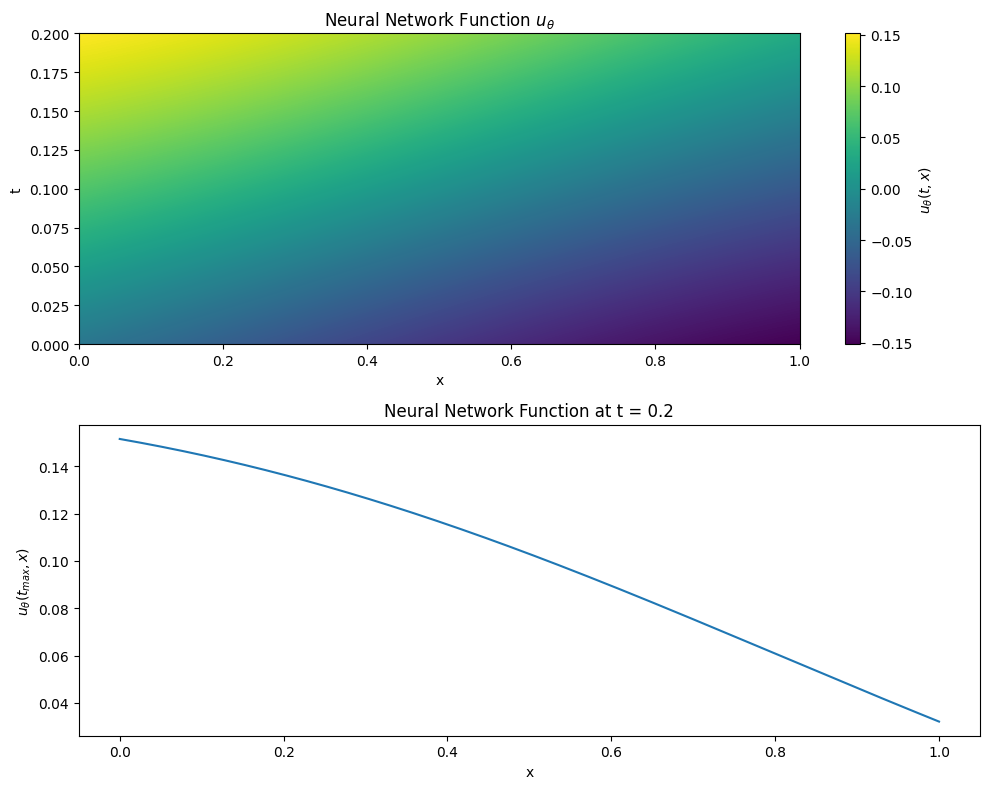


Training segment [0.0000, 0.2000]

Starting Train Stage with MGDL

Stage 1: Sequential Grade Training

Training Grade 0
Grade 0, Iter 0, lambda_ic: 9.289322, lambda_bc: 10.293939, lambda_eqn: 1.073286
Grade 0, Iter 0, loss_eqn: 0.198439, loss_eqn_from_kh: 0.198436, loss_eqn_abs: 0.198436, loss_ibc: 0.397018


In [ ]:
seq_trainer.train_seq()

In [ ]:
if not False and True:
    print(1)